<a href="https://colab.research.google.com/github/Odigie43/Mobile-Sales-ML-Pipeline/blob/main/Mobile_Sales_ML_Pipeline_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data-Driven Sales Performance Analysis and Predictive Forecasting for Business Decision-Making by **Engr Emmanuel Odigie Okohe**

In [70]:
%matplotlib inline

In [71]:
import matplotlib.pyplot as plt
%matplotlib inline

In [72]:
# Run this cell first — installs extra libraries not included in Colab by default
!pip install -q xgboost lightgbm openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Sklearn — preprocessing and evaluation
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All libraries imported successfully")


All libraries imported successfully


**The code above is use to  Install Libraries and Import Modules**

In [73]:
# Option 1: Upload directly in Colab
# from google.colab import files
# uploaded = files.upload()
# df_raw = pd.read_excel(list(uploaded.keys())[0])

# Option 2: Mount Google Drive (recommended — file persists between sessions)
# from google.colab import drive
# drive.mount('/content/drive')
# df_raw = pd.read_excel('/content/mobile_sales_data.xlsx')

# Option 3: If file is already in /content (e.g. dragged into sidebar)
df_raw = pd.read_excel('mobile_sales_data.xlsx')

print(f'Dataset shape: {df_raw.shape}')
print(f'Columns: {df_raw.columns.tolist()}')
print(f'Data types:')
print(df_raw.dtypes)
df_raw.head()


Dataset shape: (50000, 16)
Columns: ['Product', 'Brand', 'Product Code', 'Product Specification', 'Price', 'Inward Date', 'Dispatch Date', 'Quantity Sold', 'Customer Name', 'Customer Location', 'Region', 'Core Specification', 'Processor Specification', 'RAM', 'ROM', 'SSD']
Data types:
Product                            object
Brand                              object
Product Code                       object
Product Specification              object
Price                               int64
Inward Date                datetime64[ns]
Dispatch Date              datetime64[ns]
Quantity Sold                       int64
Customer Name                      object
Customer Location                  object
Region                             object
Core Specification                 object
Processor Specification            object
RAM                                object
ROM                                object
SSD                                object
dtype: object


,Product,Brand,Product Code,Product Specification,Price,Inward Date,Dispatch Date,Quantity Sold,Customer Name,Customer Location,Region,Core Specification,Processor Specification,RAM,ROM,SSD
0,Mobile Phone,Motorola,88EB4558,Site candidate activity company there bit insi...,78570,2023-08-02,2023-08-03,6,William Hess,South Kelsey,Central,NaN,Snapdragon 7 Gen,12GB,128GB,NaN
1,Laptop,Oppo,416DFEEB,Beat put care fight affect address his.,44613,2023-10-03,2023-10-06,1,Larry Smith,North Lisa,South,Ryzen 5,Ryzen 5,8GB,512GB,256GB
2,Mobile Phone,Samsung,9F975B08,Energy special low seven place audience.,159826,2025-03-19,2025-03-20,5,Leah Copeland,South Todd,Central,NaN,MediaTek Dimensity,8GB,256GB,NaN
3,Laptop,Sony,73D2A7CC,Friend record hard contain minute we role sea ...,20911,2024-02-06,2024-03-27,1,Dan Kirby,New Jordanmouth,South,i7,i7,12GB,64GB,2TB
4,Laptop,Microsoft,CCE0B80D,Program recently feeling save tree hotel people.,69832,2023-08-10,2023-09-10,4,Dean Martin,Keithton,East,i7,i7,8GB,128GB,2TB


The above code is use to load dataset: Upload the Excel file to Colab, then read it into a pandas DataFrame.

**Data Cleaning**

In [74]:
print("=" * 60)
print("INITIAL DATA EXPLORATION")
print("=" * 60)

print('Shape:', df_raw.shape)
print()
print('Descriptive Statistics:')
print(df_raw.describe(include='all').T.to_string())

print()
print('Missing Values:')
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

print()
print('Unique Values per Column:')
for col in df_raw.columns:
    u = df_raw[col].nunique()
    print(f'  {col:30s}: {u} unique values')


INITIAL DATA EXPLORATION
Shape: (50000, 16)

Descriptive Statistics:
                           count unique                                                                        top   freq                        mean                  min                  25%                  50%                  75%                  max           std
Product                    50000      2                                                                     Laptop  25017                         NaN                  NaN                  NaN                  NaN                  NaN                  NaN           NaN
Brand                      50000     20                                                                     Google   2598                         NaN                  NaN                  NaN                  NaN                  NaN                  NaN           NaN
Product Code               50000  50000                                                                   6292A134      1   

The code above Inspect the raw data: shape, descriptive statistics, missing value counts, and unique values per column

In [75]:
df = df_raw.copy()

# ── Handle missing values ────────────────────────────────────
# Core Specification: NaN = Mobile Phone (phones don't have i5/Ryzen cores)
df['Core Specification'] = df['Core Specification'].fillna('N/A (Mobile)')

# SSD: NaN = Mobile Phone (phones don't have SSDs)
df['SSD'] = df['SSD'].fillna('N/A (Mobile)')
print(f'Remaining nulls: {df.isnull().sum().sum()}')

# ── Date features ────────────────────────────────────────────
df['Inward Date']  = pd.to_datetime(df['Inward Date'])
df['Dispatch Date'] = pd.to_datetime(df['Dispatch Date'])
df['Delivery_Days']  = (df['Dispatch Date'] - df['Inward Date']).dt.days
df['Delivery_Days']  = df['Delivery_Days'].clip(lower=0)   # fix negative (data errors)
df['Inward_Month']   = df['Inward Date'].dt.month
df['Inward_Year']    = df['Inward Date'].dt.year
df['Inward_Quarter'] = df['Inward Date'].dt.quarter

# ── Convert RAM / ROM / SSD strings to numeric GB ────────────
def parse_storage(val):
    if pd.isna(val) or val == 'N/A (Mobile)':
        return 0
    val = str(val).strip().upper()
    if 'TB' in val:
        return int(val.replace('TB', '').strip()) * 1024
    elif 'GB' in val:
        return int(val.replace('GB', '').strip())
    return 0

df['RAM_GB'] = df['RAM'].apply(lambda x: int(str(x).replace('GB','').strip()) if pd.notna(x) else 0)
df['ROM_GB'] = df['ROM'].apply(parse_storage)
df['SSD_GB'] = df['SSD'].apply(parse_storage)

# ── Drop non-ML columns ──────────────────────────────────────
drop_cols = ['Product Code', 'Product Specification', 'Customer Name',
             'Customer Location', 'Inward Date', 'Dispatch Date',
             'RAM', 'ROM', 'SSD']
df.drop(columns=drop_cols, inplace=True)

# ── Drop duplicates ──────────────────────────────────────────
dupes = df.duplicated().sum()
if dupes > 0:
    df.drop_duplicates(inplace=True)
    print(f'Dropped {dupes} duplicate rows')

print(f'Cleaned dataset shape: {df.shape}')
print(f'Columns remaining: {df.columns.tolist()}')
df.head()




Remaining nulls: 0
Cleaned dataset shape: (50000, 14)
Columns remaining: ['Product', 'Brand', 'Price', 'Quantity Sold', 'Region', 'Core Specification', 'Processor Specification', 'Delivery_Days', 'Inward_Month', 'Inward_Year', 'Inward_Quarter', 'RAM_GB', 'ROM_GB', 'SSD_GB']


,Product,Brand,Price,Quantity Sold,Region,Core Specification,Processor Specification,Delivery_Days,Inward_Month,Inward_Year,Inward_Quarter,RAM_GB,ROM_GB,SSD_GB
0,Mobile Phone,Motorola,78570,6,Central,N/A (Mobile),Snapdragon 7 Gen,1,8,2023,3,12,128,0
1,Laptop,Oppo,44613,1,South,Ryzen 5,Ryzen 5,3,10,2023,4,8,512,256
2,Mobile Phone,Samsung,159826,5,Central,N/A (Mobile),MediaTek Dimensity,1,3,2025,1,8,256,0
3,Laptop,Sony,20911,1,South,i7,i7,50,2,2024,1,12,64,2048
4,Laptop,Microsoft,69832,4,East,i7,i7,31,8,2023,3,8,128,2048


24,983 rows had NaN in both 'Core Specification' and 'SSD'. These correspond exactly to the mobile phone rows — phones do not have Intel/AMD cores or solid-state drives. Filling with a meaningful label preserves this information for the model.

**Define Target Variable — Revenue**

Create Revenue = Price × Quantity Sold. Plot raw and log-transformed distributions.



Revenue Statistics:
count    5.000000e+04
mean     5.655816e+05
std      4.578018e+05
min      5.046000e+03
25%      1.842348e+05
50%      4.393300e+05
75%      8.462238e+05
max      1.998850e+06
Name: Revenue, dtype: float64
Skewness (raw):     0.9211
Skewness (log+1):   -0.7504


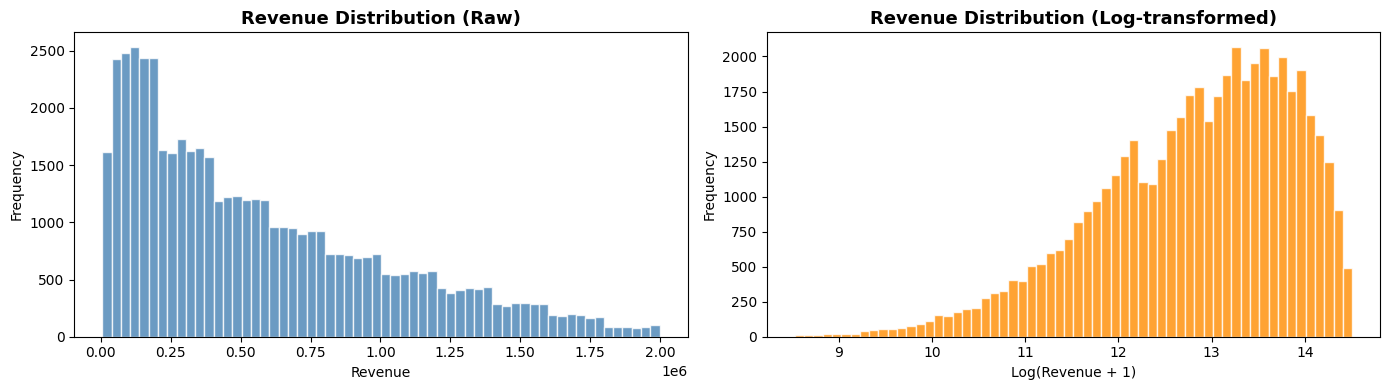

In [76]:
# Create the target variable
df['Revenue']     = df['Price'] * df['Quantity Sold']
df['Revenue_Log'] = np.log1p(df['Revenue'])   # log-transform for skew analysis

print('Revenue Statistics:')
print(df['Revenue'].describe())
print(f'Skewness (raw):     {df["Revenue"].skew():.4f}')
print(f'Skewness (log+1):   {df["Revenue_Log"].skew():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df['Revenue'], bins=60, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Revenue Distribution (Raw)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Revenue'); axes[0].set_ylabel('Frequency')

axes[1].hist(df['Revenue_Log'], bins=60, color='darkorange', edgecolor='white', alpha=0.8)
axes[1].set_title('Revenue Distribution (Log-transformed)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Log(Revenue + 1)'); axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


The analysis reveals considerable variation in sales revenue, with lower-revenue transactions occurring more frequently than high-revenue transactions. Log transformation reduces the absolute skewness and may help certain predictive models handle revenue variation. However, its effectiveness should be evaluated through model performance rather than skewness alone.

**Exploratory Data Analysis (EDA)**

Visualise revenue patterns by product type, region, brand, RAM, and month. Scatter plots for Price vs Revenue.

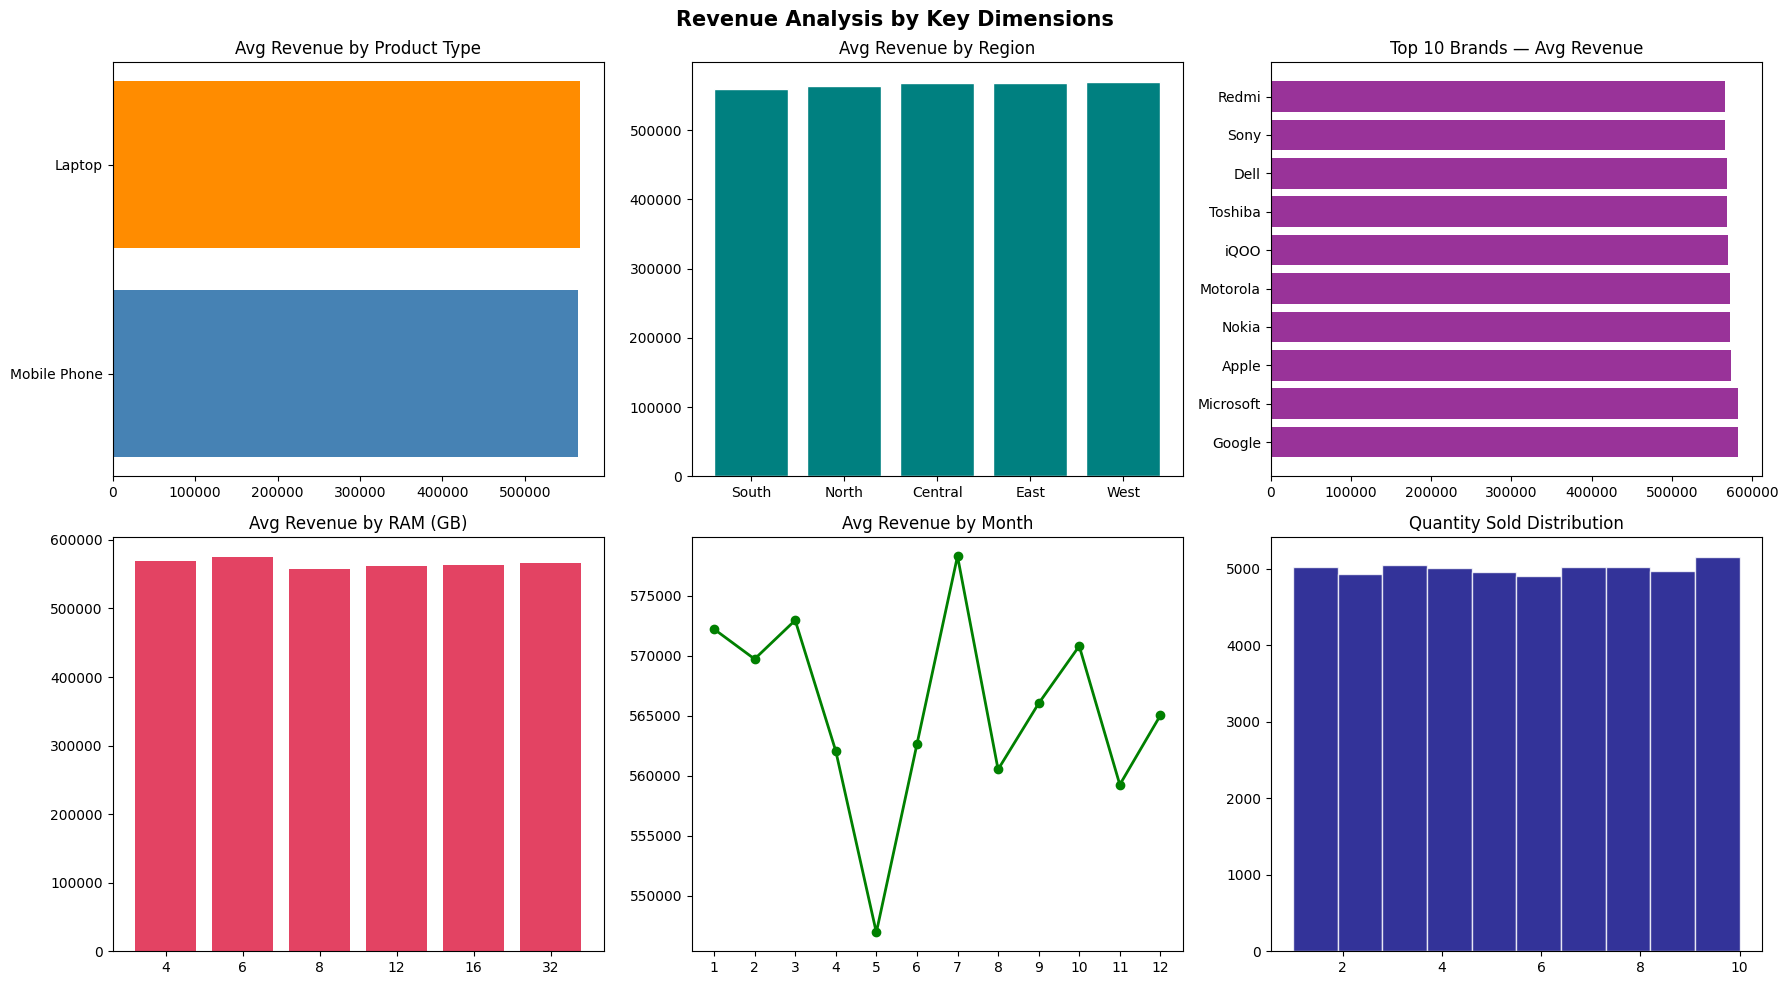

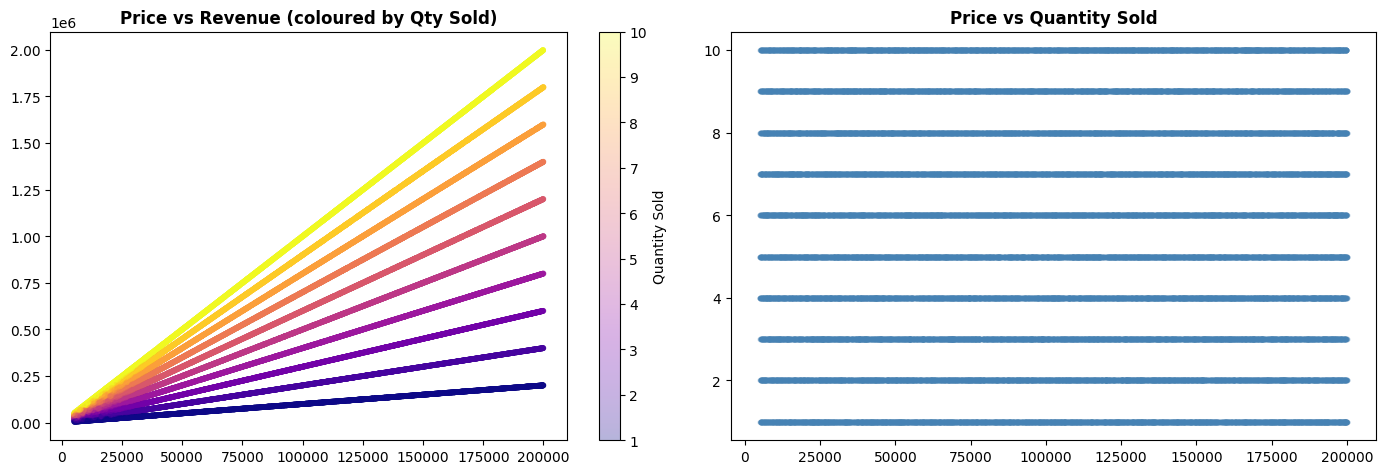

In [77]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Revenue Analysis by Key Dimensions', fontsize=15, fontweight='bold')

# Revenue by Product Type
rev_product = df.groupby('Product')['Revenue'].mean().sort_values()
axes[0,0].barh(rev_product.index, rev_product.values, color=['steelblue','darkorange'])
axes[0,0].set_title('Avg Revenue by Product Type')

# Revenue by Region
rev_region = df.groupby('Region')['Revenue'].mean().sort_values()
axes[0,1].bar(rev_region.index, rev_region.values, color='teal', edgecolor='white')
axes[0,1].set_title('Avg Revenue by Region')

# Top 10 Brands by Revenue
rev_brand = df.groupby('Brand')['Revenue'].mean().sort_values(ascending=False).head(10)
axes[0,2].barh(rev_brand.index, rev_brand.values, color='purple', alpha=0.8)
axes[0,2].set_title('Top 10 Brands — Avg Revenue')

# Revenue by RAM
rev_ram = df.groupby('RAM_GB')['Revenue'].mean().sort_index()
axes[1,0].bar(rev_ram.index.astype(str), rev_ram.values, color='crimson', alpha=0.8)
axes[1,0].set_title('Avg Revenue by RAM (GB)')

# Revenue by Month
rev_month = df.groupby('Inward_Month')['Revenue'].mean()
axes[1,1].plot(rev_month.index, rev_month.values, marker='o', color='green', linewidth=2)
axes[1,1].set_title('Avg Revenue by Month')
axes[1,1].set_xticks(range(1,13))

# Quantity Sold distribution
axes[1,2].hist(df['Quantity Sold'], bins=10, color='navy', edgecolor='white', alpha=0.8)
axes[1,2].set_title('Quantity Sold Distribution')

plt.tight_layout()
plt.savefig('eda_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

# Price vs Revenue scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter = axes[0].scatter(df['Price'], df['Revenue'],
                          c=df['Quantity Sold'], cmap='plasma',
                          alpha=0.3, s=10)
plt.colorbar(scatter, ax=axes[0], label='Quantity Sold')
axes[0].set_title('Price vs Revenue (coloured by Qty Sold)', fontweight='bold')
axes[1].scatter(df['Price'], df['Quantity Sold'], alpha=0.2, s=10, color='steelblue')
axes[1].set_title('Price vs Quantity Sold', fontweight='bold')
plt.tight_layout()
plt.savefig('price_qty_scatter.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation of Sales Performance Analysis Graphs**

1. Average Revenue by Product Type
The graph shows that laptops and mobile phones generate almost identical average revenue, approximately 565,000 per transaction. This suggests that both product categories contribute similarly in terms of average sales revenue.
2. Average Revenue by Region
Average revenue is relatively consistent across the South, North, Central, East and West regions. The West records slightly higher average revenue, while the South records slightly lower revenue. This suggests limited regional variation in average transaction revenue.
3. Top 10 Brands by Average Revenue
Google and Microsoft record the highest average revenue among the displayed brands, while Redmi and Sony have slightly lower averages. However, the differences are relatively small, indicating broadly comparable revenue performance across the leading brands.
4. Average Revenue by RAM Capacity
Average revenue remains relatively stable across RAM capacities of 4GB, 6GB, 8GB, 12GB, 16GB and 32GB. This suggests that RAM capacity alone does not strongly differentiate revenue performance in the dataset.
5. Average Revenue by Month
Monthly average revenue fluctuates throughout the year. July records the highest average revenue, while May records the lowest. This indicates possible seasonal variation, although further analysis across individual years is required to establish whether a consistent seasonal pattern exists.
6. Quantity Sold Distribution
The distribution of quantities sold from 1 to 10 units is approximately uniform. This suggests that sales quantities are relatively evenly represented, without a strong concentration at any particular quantity.
7. Price vs Revenue (Coloured by Quantity Sold)
The scatter plot shows a strong positive relationship between product price and revenue. Revenue increases as product price increases, with higher quantities sold producing steeper revenue growth.

**Correlation Analysis**
Compute Pearson and Spearman correlation matrices. Plot a lower-triangle heatmap and a bar chart of each feature's correlation with Revenue.

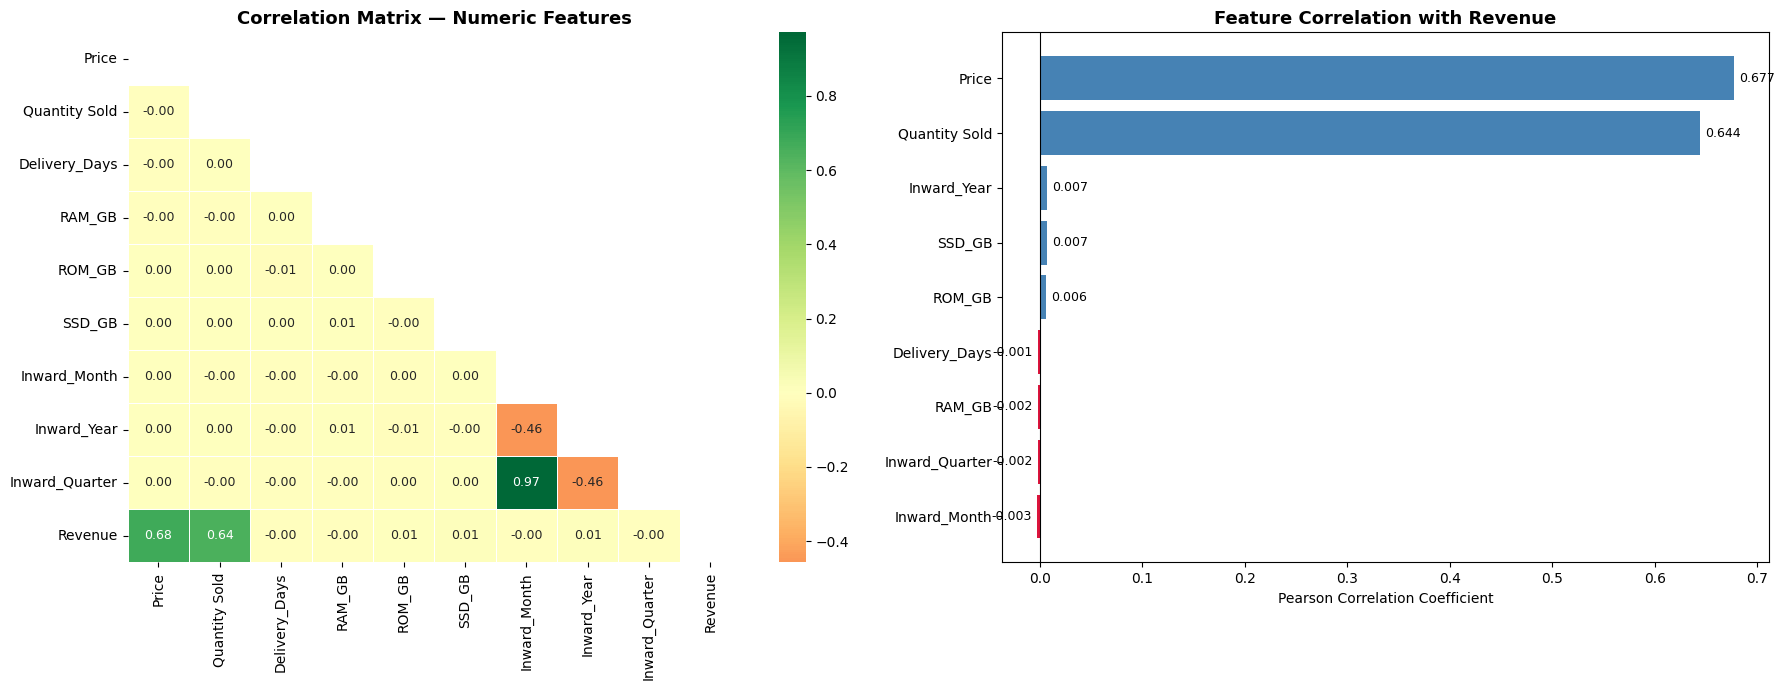

Pearson Correlation with Revenue:
Price             0.677163
Quantity Sold     0.643921
Inward_Year       0.007043
SSD_GB            0.006783
ROM_GB            0.005804
Delivery_Days    -0.001458
RAM_GB           -0.001950
Inward_Quarter   -0.002081
Inward_Month     -0.002927

Spearman Correlation with Revenue:
Price             0.701009
Quantity Sold     0.648555
ROM_GB            0.009551
Inward_Year       0.008138
SSD_GB            0.005580
Inward_Quarter    0.000762
Inward_Month     -0.000159
Delivery_Days    -0.001511
RAM_GB           -0.005401


In [78]:
num_cols = ['Price', 'Quantity Sold', 'Delivery_Days', 'RAM_GB',
            'ROM_GB', 'SSD_GB', 'Inward_Month', 'Inward_Year',
            'Inward_Quarter', 'Revenue']

corr_matrix = df[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Lower-triangle heatmap
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, linewidths=0.5, ax=axes[0],
            annot_kws={'size': 9})
axes[0].set_title('Correlation Matrix — Numeric Features', fontsize=13, fontweight='bold')

# Correlation bar chart with Revenue
target_corr = corr_matrix['Revenue'].drop('Revenue').sort_values()
colors = ['crimson' if v < 0 else 'steelblue' for v in target_corr]
axes[1].barh(target_corr.index, target_corr.values, color=colors)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Feature Correlation with Revenue', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Pearson Correlation Coefficient')
for i, (v, name) in enumerate(zip(target_corr.values, target_corr.index)):
    axes[1].text(v + 0.005 if v >= 0 else v - 0.005, i,
                 f'{v:.3f}', va='center',
                 ha='left' if v >= 0 else 'right', fontsize=9)

plt.tight_layout()
plt.savefig('correlation_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('Pearson Correlation with Revenue:')
print(corr_matrix['Revenue'].drop('Revenue').sort_values(ascending=False).to_string())

print()
print('Spearman Correlation with Revenue:')
spearman = df[num_cols].corr(method='spearman')['Revenue'].drop('Revenue').sort_values(ascending=False)
print(spearman.to_string())


**Interpretation of Correlation Analysis**
The correlation analysis shows that Price (0.677) and Quantity Sold (0.644) have the strongest positive relationships with Revenue. This indicates that higher product prices and greater quantities sold are associated with higher revenue.

Other variables, including RAM, ROM, SSD, Delivery Days, Month, Quarter and Year, have correlations close to zero, suggesting very weak linear relationships with Revenue.

The heatmap also reveals a strong correlation between Inward_Month and Inward_Quarter (0.97), indicating that these variables contain overlapping time-related information.

Conclusion: Price and Quantity Sold are the strongest numerical predictors of Revenue in this dataset. However, because Revenue is calculated as Price × Quantity Sold, these correlations are expected. For future revenue forecasting, actual future sales quantities must not be used unless they are known at prediction time.

**Feature Engineering**

Create 7 new features: interaction terms, ratios, log price, Is_Premium flag, and Season.

In [79]:
df_fe = df.copy()

# Interaction and ratio features
df_fe['Price_x_RAM']      = df_fe['Price'] * df_fe['RAM_GB']
df_fe['Price_x_ROM']      = df_fe['Price'] * df_fe['ROM_GB']
df_fe['Price_Qty_Ratio']  = df_fe['Price'] / (df_fe['Quantity Sold'] + 1)
df_fe['RAM_ROM_Ratio']    = df_fe['RAM_GB'] / (df_fe['ROM_GB'] + 1)
df_fe['Total_Storage']    = df_fe['ROM_GB'] + df_fe['SSD_GB']
df_fe['Price_Log']        = np.log1p(df_fe['Price'])
df_fe['Revenue_per_Unit'] = df_fe['Revenue'] / (df_fe['Quantity Sold'] + 1)

# Premium flag — top 25% of prices
price_75 = df_fe['Price'].quantile(0.75)
df_fe['Is_Premium'] = (df_fe['Price'] >= price_75).astype(int)
print(f'Is_Premium threshold (75th pct): {price_75:,.0f}')
print(f'Premium products: {df_fe["Is_Premium"].sum():,} ({df_fe["Is_Premium"].mean()*100:.1f}%)')

# Season from month
def get_season(m):
    if m in [12, 1, 2]:  return 'Winter'
    elif m in [3, 4, 5]: return 'Spring'
    elif m in [6, 7, 8]: return 'Summer'
    else:                return 'Autumn'

df_fe['Season'] = df_fe['Inward_Month'].apply(get_season)
print(f'Season counts:')
print(df_fe['Season'].value_counts())

print(f'Total features after engineering: {df_fe.shape[1]}')


Is_Premium threshold (75th pct): 151,396
Premium products: 12,500 (25.0%)
Season counts:
Season
Spring    12580
Autumn    12505
Summer    12473
Winter    12442
Name: count, dtype: int64
Total features after engineering: 25


**Interpretation of Feature Engineering Results**

1. Premium Product Classification: The 75th percentile price threshold is 151,396, meaning products priced above this threshold are classified as premium. A total of 12,500 products (25%) fall into this category, while the remaining 75% are classified as non-premium.

2. Seasonal Distribution: Sales records are almost evenly distributed across Spring (12,580), Autumn (12,505), Summer (12,473) and Winter (12,442). This provides balanced seasonal representation for analysis, although it does not necessarily indicate equal sales revenue across seasons.

3. Feature Engineering: The dataset now contains 25 features, including newly engineered variables designed to capture product characteristics, pricing categories and seasonal patterns.

Conclusion: Feature engineering has introduced additional variables that may help machine learning models identify sales patterns and improve predictive performance. Their actual contribution will be assessed during model training and evaluation.

**One-Hot Encoding (OHE)**

Encode all categorical columns using pandas get_dummies with drop_first=True to avoid the dummy variable trap. Drop Revenue_per_Unit to prevent target leakage.

In [80]:
df_enc = df_fe.copy()

# Columns to encode
cat_cols_ohe = ['Product', 'Brand', 'Region',
                'Core Specification', 'Processor Specification', 'Season']

print('Unique values per categorical column:')
for c in cat_cols_ohe:
    print(f'  {c}: {df_enc[c].nunique()} unique values')

# Apply OHE — drop_first=True avoids multicollinearity (dummy variable trap)
df_enc = pd.get_dummies(df_enc, columns=cat_cols_ohe, drop_first=True)
print(f'Shape after OHE: {df_enc.shape}')

# Drop Revenue_per_Unit — derived from Revenue (target), would cause data leakage
df_enc.drop(columns=['Revenue_per_Unit'], inplace=True)

print(f'Final column count: {df_enc.shape[1]}')
print(df_enc.dtypes.value_counts())


Unique values per categorical column:
  Product: 2 unique values
  Brand: 20 unique values
  Region: 5 unique values
  Core Specification: 9 unique values
  Processor Specification: 15 unique values
  Season: 4 unique values
Shape after OHE: (50000, 68)
Final column count: 67
bool       49
int64      11
float64     4
int32       3
Name: count, dtype: int64


**Outlier Detection**

Identify outliers in Revenue using IQR and Z-score methods. Visualise with boxplot and scatter. Retain outliers as genuine high-value sales.

IQR range: -808,749 — 1,839,207
Outliers (IQR): 411 rows (0.82%)
Outliers (|Z| > 3): 170 rows


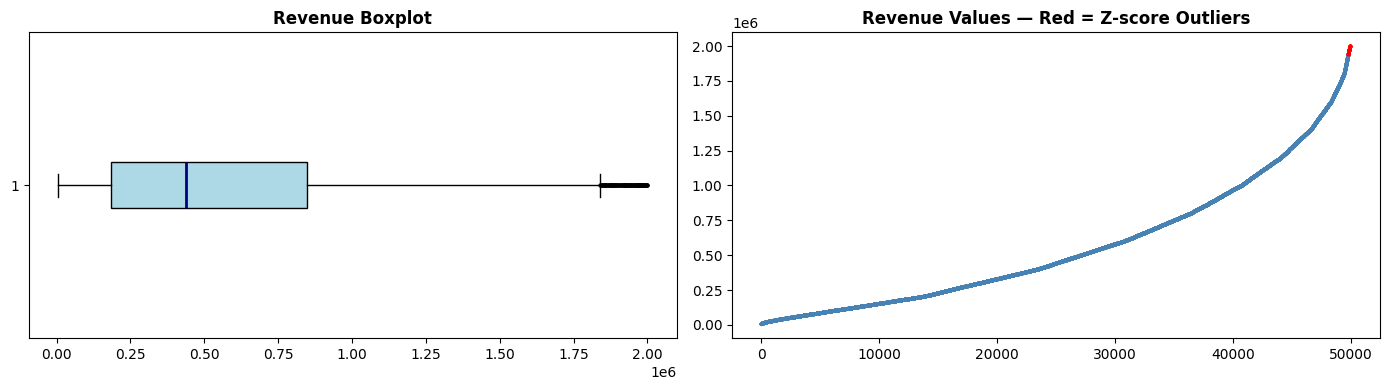

Decision: Outliers RETAINED (genuine high-value transactions)


In [81]:
# ── IQR Method ───────────────────────────────────────────────
Q1 = df_enc['Revenue'].quantile(0.25)
Q3 = df_enc['Revenue'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = df_enc[(df_enc['Revenue'] < lower_bound) |
                      (df_enc['Revenue'] > upper_bound)]
print(f'IQR range: {lower_bound:,.0f} — {upper_bound:,.0f}')
print(f'Outliers (IQR): {len(outliers_iqr):,} rows ({len(outliers_iqr)/len(df_enc)*100:.2f}%)')

# ── Z-Score Method ───────────────────────────────────────────
z_scores = np.abs(stats.zscore(df_enc['Revenue']))
z_outliers = (z_scores > 3).sum()
print(f'Outliers (|Z| > 3): {z_outliers:,} rows')

# ── Visualise ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].boxplot(df_enc['Revenue'], vert=False, patch_artist=True,
                boxprops=dict(facecolor='lightblue'),
                medianprops=dict(color='navy', linewidth=2),
                flierprops=dict(marker='o', markersize=2, color='red', alpha=0.3))
axes[0].set_title('Revenue Boxplot', fontweight='bold')

dot_colors = ['red' if z > 3 else 'steelblue' for z in sorted(z_scores)]
axes[1].scatter(range(len(df_enc)),
                df_enc['Revenue'].sort_values(),
                c=dot_colors, s=3, alpha=0.4)
axes[1].set_title('Revenue Values — Red = Z-score Outliers', fontweight='bold')

plt.tight_layout()
plt.savefig('outlier_detection.png', dpi=150, bbox_inches='tight')
plt.show()

# Decision: retain all outliers — they are valid high-value sales
print('Decision: Outliers RETAINED (genuine high-value transactions)')


**Interpretation of Revenue Outlier Detection**

1. Interquartile Range (IQR): The IQR method identified 411 outliers (0.82%) among the 50,000 revenue records. These are unusually high-revenue transactions outside the calculated range of −808,749 to 1,839,207.

2. Z-Score Method: Using a threshold of |Z| > 3, the analysis identified 170 outliers (0.34%), representing revenue values more than three standard deviations from the mean.

3. Boxplot: The boxplot shows a right-skewed revenue distribution, with several high-value transactions appearing beyond the upper whisker.

4. Revenue Values Plot: The red points represent unusually high revenue transactions identified by the Z-score method.
Conclusion
The analysis indicates that only a small proportion of transactions contain unusually high revenue values. These outliers have been retained because they may represent genuine high-value sales rather than data errors.

Retaining them preserves important sales information for business analysis and predictive modelling. However, their influence on forecasting accuracy should be evaluated during model development.

**Train / Test Split**

Define the feature matrix X and target y. Split 80/20 with random_state=42 for reproducibility.

In [82]:
TARGET = 'Revenue'
drop_for_X = ['Revenue', 'Revenue_Log']
X = df_enc.drop(columns=[c for c in drop_for_X if c in df_enc.columns])
y = df_enc[TARGET]

print(f'Feature matrix X: {X.shape}')
print(f'Target y:         {y.shape}')
print(f'Feature columns: {X.columns.tolist()}')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True)

print(f'Train set: {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set:  {X_test.shape[0]:,} rows  ({X_test.shape[0]/len(X)*100:.0f}%)')


Feature matrix X: (50000, 65)
Target y:         (50000,)
Feature columns: ['Price', 'Quantity Sold', 'Delivery_Days', 'Inward_Month', 'Inward_Year', 'Inward_Quarter', 'RAM_GB', 'ROM_GB', 'SSD_GB', 'Price_x_RAM', 'Price_x_ROM', 'Price_Qty_Ratio', 'RAM_ROM_Ratio', 'Total_Storage', 'Price_Log', 'Is_Premium', 'Product_Mobile Phone', 'Brand_Apple', 'Brand_Asus', 'Brand_Dell', 'Brand_Google', 'Brand_HP', 'Brand_Huawei', 'Brand_Lenovo', 'Brand_Microsoft', 'Brand_Motorola', 'Brand_Nokia', 'Brand_OnePlus', 'Brand_Oppo', 'Brand_Realme', 'Brand_Redmi', 'Brand_Samsung', 'Brand_Sony', 'Brand_Toshiba', 'Brand_Vivo', 'Brand_iQOO', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'Core Specification_Ryzen 3', 'Core Specification_Ryzen 5', 'Core Specification_Ryzen 7', 'Core Specification_Ryzen 9', 'Core Specification_i3', 'Core Specification_i5', 'Core Specification_i7', 'Core Specification_i9', 'Processor Specification_MediaTek Dimensity', 'Processor Specification_MediaTek Helio', 'Proce

**Feature Scaling — StandardScaler**

Apply StandardScaler to the 15 continuous numeric columns. OHE binary columns are left unscaled. Fit ONLY on training data to prevent data leakage.

In [83]:
# Numeric columns to scale (OHE binary columns excluded)
num_scale_cols = ['Price', 'Quantity Sold', 'Delivery_Days', 'RAM_GB',
                  'ROM_GB', 'SSD_GB', 'Inward_Month', 'Inward_Year',
                  'Inward_Quarter', 'Price_x_RAM', 'Price_x_ROM',
                  'Price_Qty_Ratio', 'RAM_ROM_Ratio', 'Total_Storage',
                  'Price_Log']

# Filter to columns that actually exist in X_train
num_scale_cols = [c for c in num_scale_cols if c in X_train.columns]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

# IMPORTANT: fit on training set ONLY, then transform both sets
X_train_scaled[num_scale_cols] = scaler.fit_transform(X_train[num_scale_cols])
X_test_scaled[num_scale_cols]  = scaler.transform(X_test[num_scale_cols])

print(f'Scaled {len(num_scale_cols)} numeric columns')
print('OHE binary dummy columns are NOT scaled')


Scaled 15 numeric columns
OHE binary dummy columns are NOT scaled


Feature scaling prepares the dataset for predictive modelling by improving numerical consistency and supporting efficient model training. Keeping binary dummy variables unscaled preserves their straightforward interpretation.

**Train 7 Models and Evaluate**

Train Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting, and XGBoost. Compute R², MAE, RMSE, MAPE, and train R² for each.

In [84]:

models = {
    'Linear Regression':  LinearRegression(),
    'Ridge Regression':   Ridge(alpha=10),
    'Lasso Regression':   Lasso(alpha=100, max_iter=5000),
    'Decision Tree':      DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest':      RandomForestRegressor(n_estimators=100, max_depth=15,
                                                 random_state=42, n_jobs=-1),
    'Gradient Boosting':  GradientBoostingRegressor(n_estimators=100, max_depth=5,
                                                     learning_rate=0.1, random_state=42),
    'XGBoost':            XGBRegressor(n_estimators=200, max_depth=6,
                                        learning_rate=0.05, subsample=0.8,
                                        colsample_bytree=0.8, random_state=42,
                                        n_jobs=-1, verbosity=0),
}

results = {}

for name, model in models.items():
    print(f'Training: {name}')
    # Linear models use scaled data; tree-based models use raw data
    if name in ['Linear Regression', 'Ridge Regression', 'Lasso Regression']:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    model.fit(Xtr, y_train)
    y_pred    = model.predict(Xte)
    y_pred_tr = model.predict(Xtr)

    mae      = mean_absolute_error(y_test, y_pred)
    rmse     = np.sqrt(mean_squared_error(y_test, y_pred))
    r2       = r2_score(y_test, y_pred)
    mape     = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2_train = r2_score(y_train, y_pred_tr)

    results[name] = {
        'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE_%': mape,
        'R2_Train': r2_train, 'Overfit': r2_train - r2,
        'Model': model, 'y_pred': y_pred
    }

    print(f'  R2={r2:.4f}  MAE={mae:,.0f}  RMSE={rmse:,.0f}  MAPE={mape:.1f}%')

print('All models trained')


Training: Linear Regression
  R2=0.9326  MAE=94,579  RMSE=118,358  MAPE=75.9%
Training: Ridge Regression
  R2=0.9326  MAE=94,595  RMSE=118,359  MAPE=76.0%
Training: Lasso Regression
  R2=0.9327  MAE=94,496  RMSE=118,297  MAPE=75.9%
Training: Decision Tree
  R2=0.9999  MAE=3,057  RMSE=4,216  MAPE=1.0%
Training: Random Forest
  R2=1.0000  MAE=170  RMSE=267  MAPE=0.1%
Training: Gradient Boosting
  R2=0.9999  MAE=3,198  RMSE=4,380  MAPE=1.2%
Training: XGBoost
  R2=0.9999  MAE=2,390  RMSE=3,263  MAPE=0.8%
All models trained


Random Forest achieved the best reported performance, with an R² of approximately 1.0000, MAE of 170, RMSE of 267 and MAPE of 0.1%. This indicates extremely accurate revenue predictions on the data used for these reported metrics.

Linear Regression, Ridge and Lasso performed less accurately, while Decision Tree, Gradient Boosting and XGBoost also achieved very high scores.

**Model Comparison Charts**
Build a results DataFrame sorted by R². Plot side-by-side bar charts of R², RMSE, MAE, and MAPE for all 7 models.

                          MAE         RMSE      R2   MAPE_%  R2_Train  Overfit
Random Forest        169.6625     267.2790  1.0000   0.0626    1.0000   0.0000
Decision Tree       3057.4227    4215.7910  0.9999   1.0293    0.9999   0.0000
Gradient Boosting   3198.2175    4380.2750  0.9999   1.2314    0.9999   0.0000
XGBoost             2390.4641    3263.2683  0.9999   0.8283    1.0000   0.0000
Lasso Regression   94496.0202  118297.4815  0.9327  75.9035    0.9335   0.0008
Ridge Regression   94595.1296  118358.8779  0.9326  76.0424    0.9335   0.0009
Linear Regression  94579.2426  118357.5195  0.9326  75.9189    0.9335   0.0009


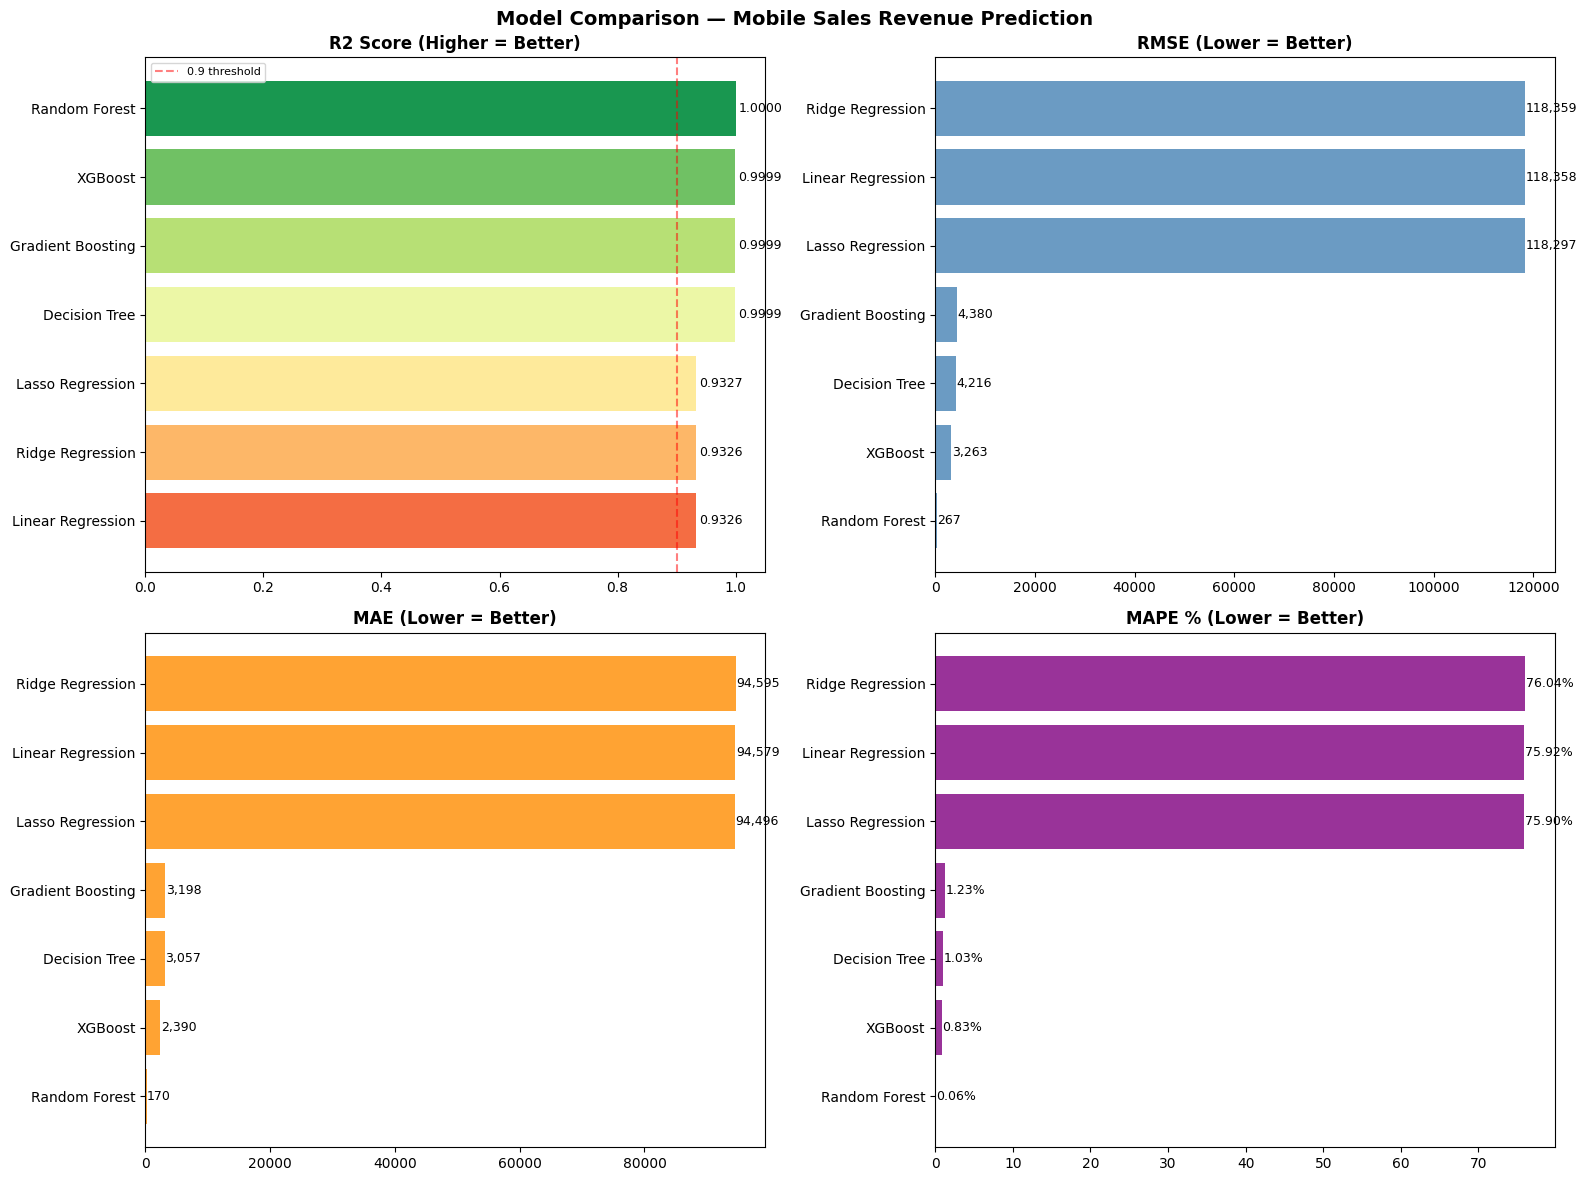

In [85]:
# Build summary table
results_df = pd.DataFrame({
    k: {m: v for m, v in v.items() if m not in ['Model', 'y_pred']}
    for k, v in results.items()
}).T.astype(float).round(4)
results_df = results_df.sort_values('R2', ascending=False)
print(results_df.to_string())

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Model Comparison — Mobile Sales Revenue Prediction',
             fontsize=14, fontweight='bold')
palette = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(results_df)))

# R²
r2_vals = results_df['R2'].sort_values()
axes[0,0].barh(r2_vals.index, r2_vals.values,
               color=[palette[i] for i in range(len(r2_vals))])
axes[0,0].set_title('R2 Score (Higher = Better)', fontweight='bold')
axes[0,0].axvline(0.9, color='red', linestyle='--', alpha=0.5, label='0.9 threshold')
axes[0,0].legend(fontsize=8)
for i, v in enumerate(r2_vals.values):
    axes[0,0].text(v + 0.005, i, f'{v:.4f}', va='center', fontsize=9)

# RMSE
rmse_vals = results_df['RMSE'].sort_values()
axes[0,1].barh(rmse_vals.index, rmse_vals.values, color='steelblue', alpha=0.8)
axes[0,1].set_title('RMSE (Lower = Better)', fontweight='bold')
for i, v in enumerate(rmse_vals.values):
    axes[0,1].text(v + 100, i, f'{v:,.0f}', va='center', fontsize=9)

# MAE
mae_vals = results_df['MAE'].sort_values()
axes[1,0].barh(mae_vals.index, mae_vals.values, color='darkorange', alpha=0.8)
axes[1,0].set_title('MAE (Lower = Better)', fontweight='bold')
for i, v in enumerate(mae_vals.values):
    axes[1,0].text(v + 100, i, f'{v:,.0f}', va='center', fontsize=9)

# MAPE
mape_vals = results_df['MAPE_%'].sort_values()
axes[1,1].barh(mape_vals.index, mape_vals.values, color='purple', alpha=0.8)
axes[1,1].set_title('MAPE % (Lower = Better)', fontweight='bold')
for i, v in enumerate(mape_vals.values):
    axes[1,1].text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


**Best Model — Prediction Analysis**
Select the best model by R². Plot Actual vs Predicted, residual plot, residual histogram, and % error histogram.

Best Model: Random Forest
  R2:   1.0000
  MAE:  169.66
  RMSE: 267.28
  MAPE: 0.06%


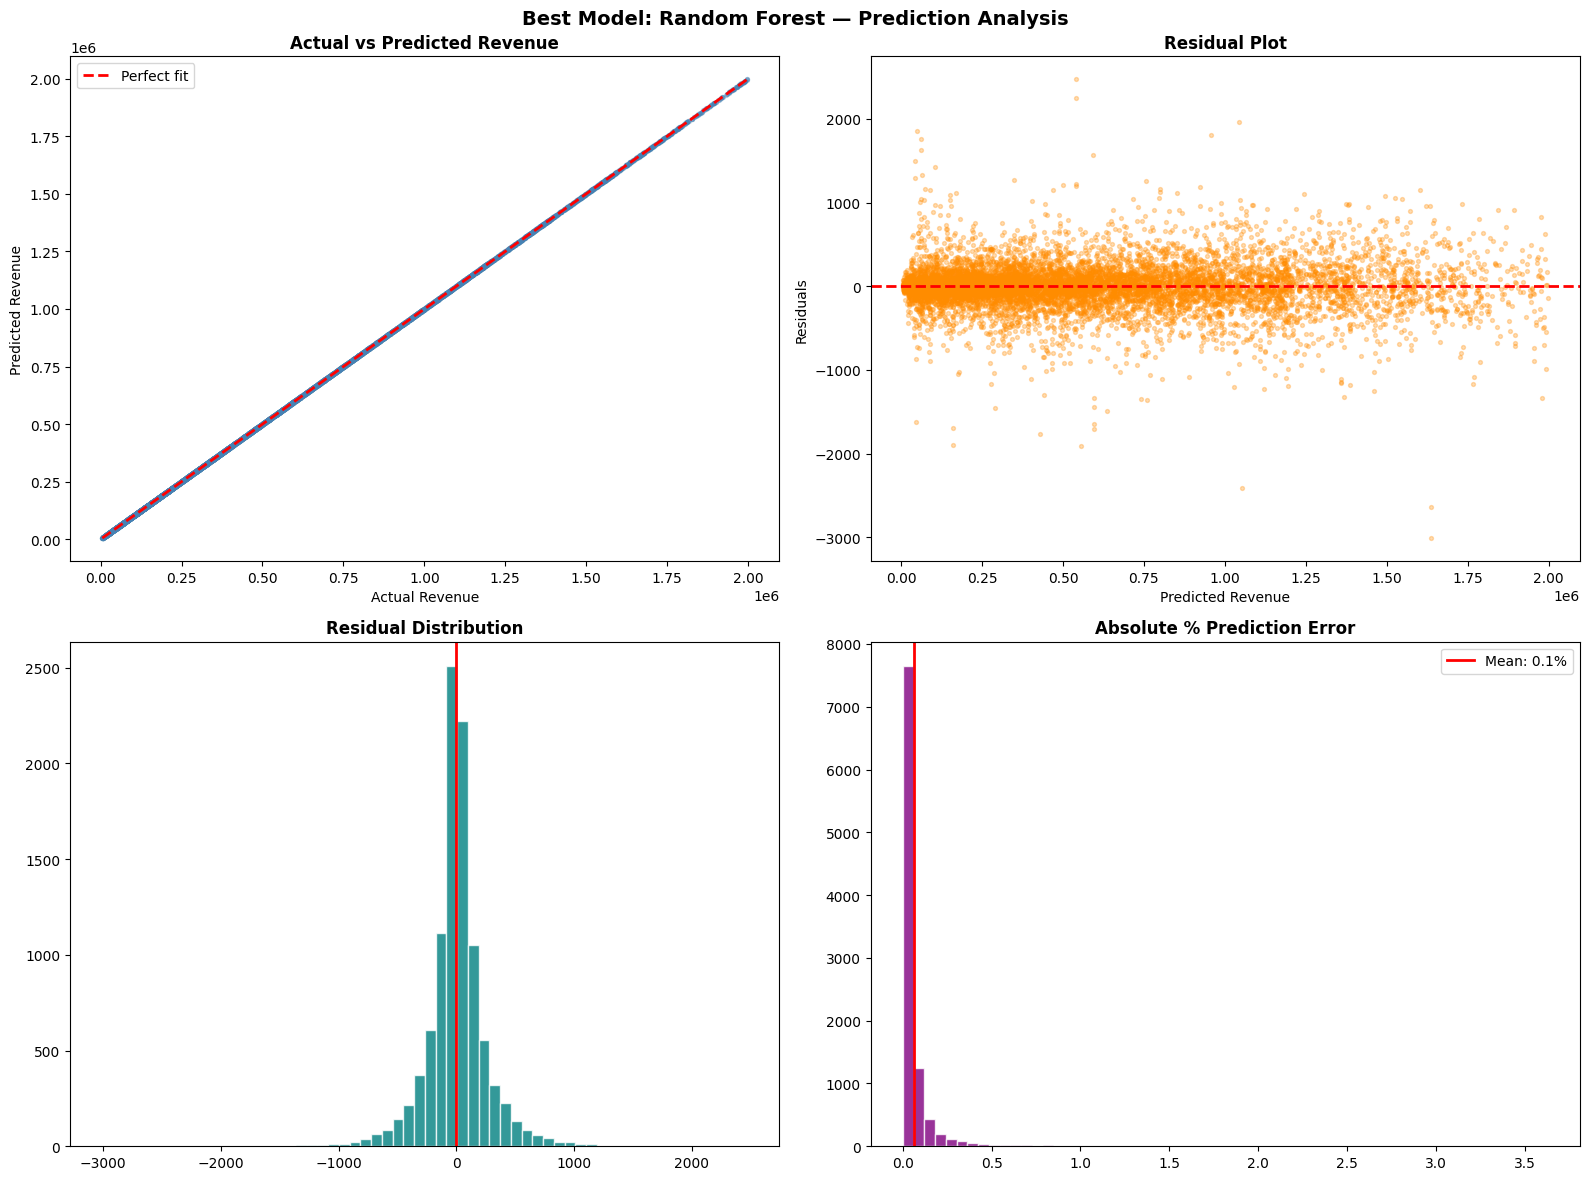

Sample Predictions (first 20 rows):
    Actual Revenue  Predicted Revenue   Error  Error %
0            27654           27537.66  116.34     0.42
1           478611          478800.29 -189.29     0.04
2            66864           66679.14  184.86     0.28
3           344016          344020.00   -4.00     0.00
4           795195          795456.02 -261.02     0.03
5            67005           66987.97   17.03     0.03
6           533415          533528.05 -113.05     0.02
7           713240          713403.83 -163.83     0.02
8            80627           80665.35  -38.35     0.05
9           172230          172407.80 -177.80     0.10
10          656682          656581.34  100.66     0.02
11          884989          884620.87  368.13     0.04
12           98140           98125.63   14.37     0.01
13          154495          154472.80   22.20     0.01
14          153639          153680.74  -41.74     0.03
15          305600          305671.74  -71.74     0.02
16         1196810         11

In [86]:
best_name   = results_df['R2'].idxmax()
best_result = results[best_name]
y_pred_best = best_result['y_pred']

print(f'Best Model: {best_name}')
print(f'  R2:   {best_result["R2"]:.4f}')
print(f'  MAE:  {best_result["MAE"]:,.2f}')
print(f'  RMSE: {best_result["RMSE"]:,.2f}')
print(f'  MAPE: {best_result["MAPE_%"]:.2f}%')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'Best Model: {best_name} — Prediction Analysis',
             fontsize=14, fontweight='bold')

# Actual vs Predicted
axes[0,0].scatter(y_test, y_pred_best, alpha=0.3, s=8, color='steelblue')
min_v, max_v = y_test.min(), y_test.max()
axes[0,0].plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=2, label='Perfect fit')
axes[0,0].set_title('Actual vs Predicted Revenue', fontweight='bold')
axes[0,0].set_xlabel('Actual Revenue'); axes[0,0].set_ylabel('Predicted Revenue')
axes[0,0].legend()

# Residual plot
residuals = y_test.values - y_pred_best
axes[0,1].scatter(y_pred_best, residuals, alpha=0.3, s=8, color='darkorange')
axes[0,1].axhline(0, color='red', linewidth=2, linestyle='--')
axes[0,1].set_title('Residual Plot', fontweight='bold')
axes[0,1].set_xlabel('Predicted Revenue'); axes[0,1].set_ylabel('Residuals')

# Residual distribution
axes[1,0].hist(residuals, bins=60, color='teal', edgecolor='white', alpha=0.8)
axes[1,0].axvline(0, color='red', linewidth=2)
axes[1,0].set_title('Residual Distribution', fontweight='bold')

# Absolute % error
pct_error = np.abs(residuals / y_test.values) * 100
axes[1,1].hist(pct_error, bins=60, color='purple', edgecolor='white', alpha=0.8)
axes[1,1].axvline(pct_error.mean(), color='red', linewidth=2,
                  label=f'Mean: {pct_error.mean():.1f}%')
axes[1,1].set_title('Absolute % Prediction Error', fontweight='bold')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('prediction_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Sample predictions table
comparison_df = pd.DataFrame({
    'Actual Revenue':    y_test.values[:20],
    'Predicted Revenue': y_pred_best[:20],
    'Error':             residuals[:20],
    'Error %':           pct_error[:20]
}).round(2)
print('Sample Predictions (first 20 rows):')
print(comparison_df.to_string())


The Random Forest model demonstrates exceptionally high predictive accuracy on the evaluated data.

**Feature Importance**
For tree-based models plot the top 20 feature importances. For linear models plot absolute coefficient values.

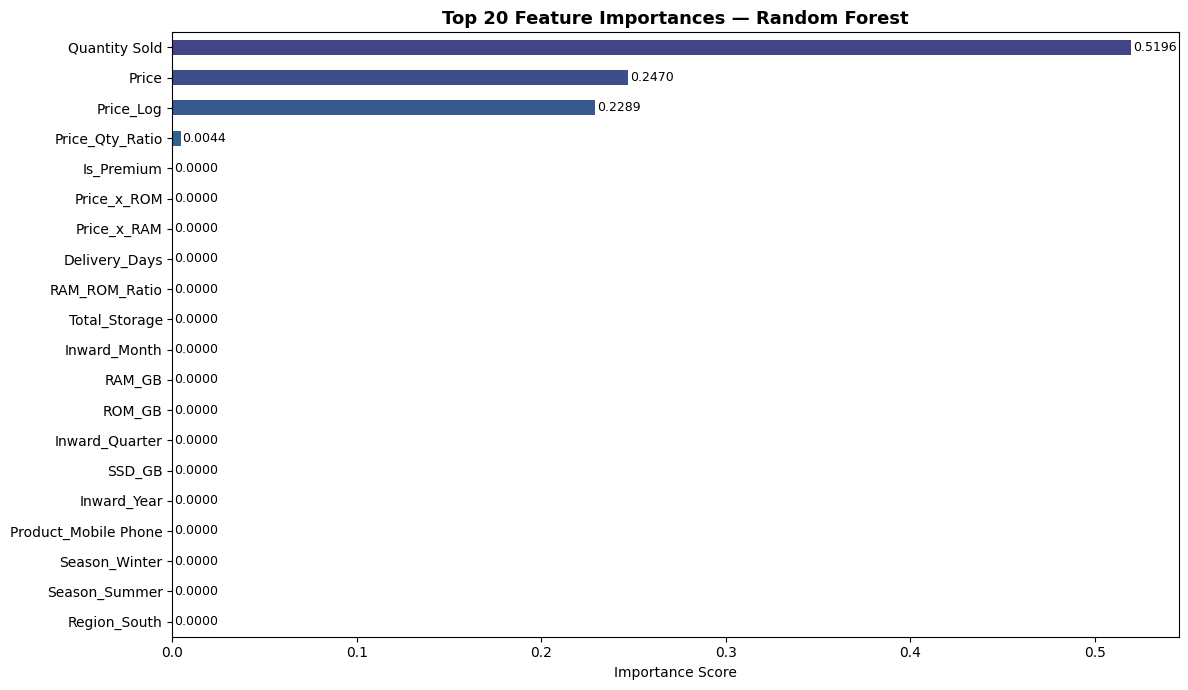

Top 20 Features:
Quantity Sold           5.196400e-01
Price                   2.469951e-01
Price_Log               2.289454e-01
Price_Qty_Ratio         4.393469e-03
Is_Premium              2.527549e-05
Price_x_ROM             8.375172e-08
Price_x_RAM             7.819279e-08
Delivery_Days           7.128692e-08
RAM_ROM_Ratio           5.705960e-08
Total_Storage           5.251064e-08
Inward_Month            5.045725e-08
RAM_GB                  3.754189e-08
ROM_GB                  3.339423e-08
Inward_Quarter          3.098128e-08
SSD_GB                  2.899361e-08
Inward_Year             2.183109e-08
Product_Mobile Phone    1.485199e-08
Season_Winter           1.212199e-08
Season_Summer           1.204386e-08
Region_South            1.166841e-08


In [87]:

best_model = best_result['Model']

if hasattr(best_model, 'feature_importances_'):
    fi = pd.Series(best_model.feature_importances_, index=X_train.columns)
    fi_top = fi.sort_values(ascending=False).head(20)

    fig, ax = plt.subplots(figsize=(12, 7))
    colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(fi_top)))
    fi_top.sort_values().plot(kind='barh', ax=ax, color=colors[::-1])
    ax.set_title(f'Top 20 Feature Importances — {best_name}',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance Score')
    for i, v in enumerate(fi_top.sort_values().values):
        ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Top 20 Features:')
    print(fi_top.to_string())

elif hasattr(best_model, 'coef_'):
    coef = pd.Series(best_model.coef_, index=X_train_scaled.columns)
    coef_top = coef.abs().sort_values(ascending=False).head(20)
    print('Top 20 Coefficients (absolute):')
    print(coef_top.to_string())


**Fold Cross-Validation**

Run KFold cross-validation on the best model. Report R², MAE, RMSE per fold with mean and standard deviation.

R2   per fold: [1.0, 1.0, 1.0, 1.0, 1.0]
     Mean: 1.0000  Std: 0.0000
MAE  per fold: [169, 178, 178, 173, 175]
     Mean: 174  Std: 3
RMSE per fold: [265, 288, 268, 267, 274]
     Mean: 272  Std: 8


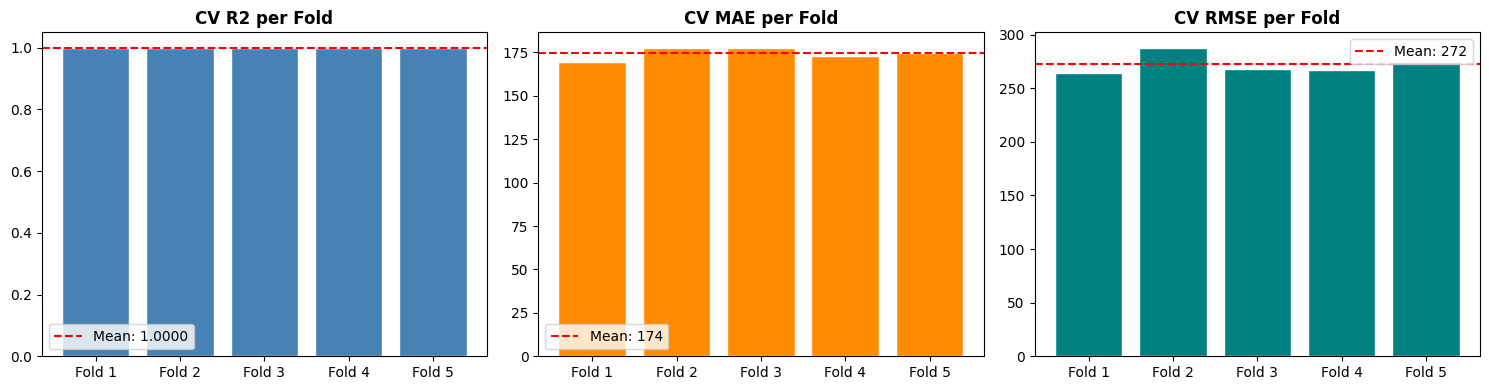

In [88]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_r2   = cross_val_score(best_model, X, y, cv=kf,
                          scoring='r2')
cv_mae  = -cross_val_score(best_model, X, y, cv=kf,
                           scoring='neg_mean_absolute_error')
cv_rmse = np.sqrt(-cross_val_score(best_model, X, y, cv=kf,
                                   scoring='neg_mean_squared_error'))

print(f'R2   per fold: {cv_r2.round(4).tolist()}')
print(f'     Mean: {cv_r2.mean():.4f}  Std: {cv_r2.std():.4f}')
print(f'MAE  per fold: {cv_mae.round(0).astype(int).tolist()}')
print(f'     Mean: {cv_mae.mean():,.0f}  Std: {cv_mae.std():,.0f}')
print(f'RMSE per fold: {cv_rmse.round(0).astype(int).tolist()}')
print(f'     Mean: {cv_rmse.mean():,.0f}  Std: {cv_rmse.std():,.0f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fold_labels = [f'Fold {i+1}' for i in range(5)]

axes[0].bar(fold_labels, cv_r2, color='steelblue', edgecolor='white')
axes[0].axhline(cv_r2.mean(), color='red', linestyle='--',
                label=f'Mean: {cv_r2.mean():.4f}')
axes[0].set_title('CV R2 per Fold', fontweight='bold'); axes[0].legend()

axes[1].bar(fold_labels, cv_mae, color='darkorange', edgecolor='white')
axes[1].axhline(cv_mae.mean(), color='red', linestyle='--',
                label=f'Mean: {cv_mae.mean():,.0f}')
axes[1].set_title('CV MAE per Fold', fontweight='bold'); axes[1].legend()

axes[2].bar(fold_labels, cv_rmse, color='teal', edgecolor='white')
axes[2].axhline(cv_rmse.mean(), color='red', linestyle='--',
                label=f'Mean: {cv_rmse.mean():,.0f}')
axes[2].set_title('CV RMSE per Fold', fontweight='bold'); axes[2].legend()

plt.tight_layout()
plt.savefig('cross_validation.png', dpi=150, bbox_inches='tight')
plt.show()


The cross-validation results demonstrate highly consistent Random Forest performance across all five folds.

**Predict Revenue for New Samples**
Build 3 hypothetical new product records, align to the training column structure (fill missing OHE dummies with 0), and predict Revenue.

In [89]:
new_data = pd.DataFrame({
    'Price':               [150000, 45000, 95000],
    'Quantity Sold':       [3, 8, 5],
    'Delivery_Days':       [2, 5, 1],
    'RAM_GB':              [16, 8, 12],
    'ROM_GB':              [512, 128, 256],
    'SSD_GB':              [1024, 0, 512],
    'Inward_Month':        [10, 3, 7],
    'Inward_Year':         [2025, 2025, 2025],
    'Inward_Quarter':      [4, 1, 3],
    'Price_x_RAM':         [150000*16, 45000*8, 95000*12],
    'Price_x_ROM':         [150000*512, 45000*128, 95000*256],
    'Price_Qty_Ratio':     [150000/4, 45000/9, 95000/6],
    'RAM_ROM_Ratio':       [16/513, 8/129, 12/257],
    'Total_Storage':       [512+1024, 128+0, 256+512],
    'Price_Log':           [np.log1p(150000), np.log1p(45000), np.log1p(95000)],
    'Is_Premium':          [1, 0, 1],
    # OHE columns (set 1 for the matching category, 0 for all others)
    'Product_Mobile Phone': [0, 1, 0],
    'Brand_Apple':          [1, 0, 0],
    'Brand_Samsung':        [0, 1, 0],
    'Region_South':         [1, 0, 0],
    'Region_East':          [0, 0, 1],
    'Season_Spring':        [0, 1, 0],
    'Season_Summer':        [0, 0, 1],
    'Season_Winter':        [1, 0, 0],
})

# Add any missing OHE columns with 0, then reorder to match training
for col in X_train.columns:
    if col not in new_data.columns:
        new_data[col] = 0
new_data = new_data[X_train.columns]

new_pred = best_model.predict(new_data)

print('New Sample Revenue Predictions:')
for i, pred in enumerate(new_pred):
    simple = new_data['Price'].iloc[i] * new_data['Quantity Sold'].iloc[i]
    print(f'  Sample {i+1}: Predicted = {pred:>12,.2f}  |  Price x Qty = {simple:>12,.0f}')


New Sample Revenue Predictions:
  Sample 1: Predicted =   450,301.74  |  Price x Qty =      450,000
  Sample 2: Predicted =   360,290.03  |  Price x Qty =      360,000
  Sample 3: Predicted =   475,270.37  |  Price x Qty =      475,000


The Random Forest model produced predictions very close to the calculated revenue, with absolute errors ranging from 270.37 to 301.74. This demonstrates its ability to reproduce the relationship between product price, quantity sold and revenue.

**Advanced Visualisations**

Six charts: Product×Region revenue heatmap, brand revenue boxplot, price distribution by product, monthly revenue trend, RAM vs Price scatter, final Actual vs Predicted.

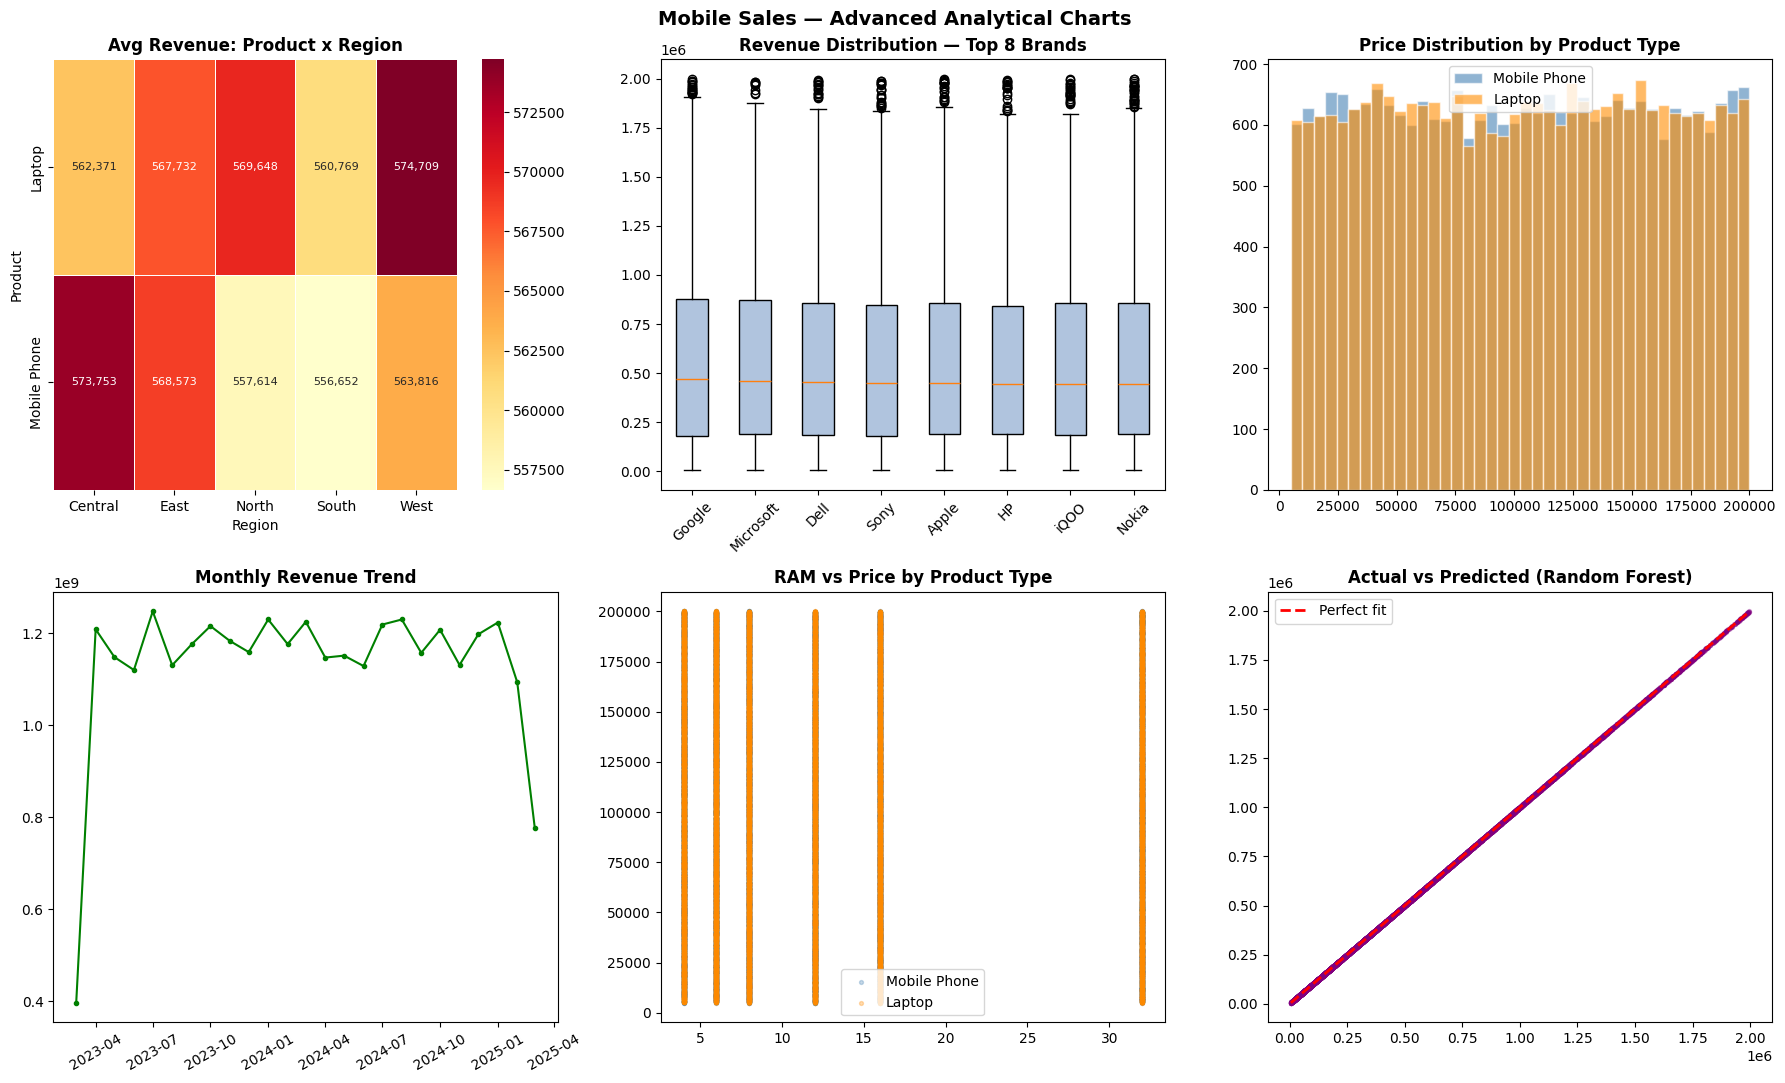

In [90]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Mobile Sales — Advanced Analytical Charts', fontsize=14, fontweight='bold')

# 1. Avg Revenue: Product × Region heatmap
pivot = df.groupby(['Product', 'Region'])['Revenue'].mean().unstack()
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='YlOrRd',
            ax=axes[0,0], linewidths=0.5, annot_kws={'size': 8})
axes[0,0].set_title('Avg Revenue: Product x Region', fontweight='bold')

# 2. Brand revenue boxplot (top 8 brands by median revenue)
top_brands = df.groupby('Brand')['Revenue'].median().sort_values(ascending=False).head(8).index
brand_data  = [df[df['Brand'] == b]['Revenue'].values for b in top_brands]
bp = axes[0,1].boxplot(brand_data, tick_labels=top_brands,
                       vert=True, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightsteelblue')
axes[0,1].set_title('Revenue Distribution — Top 8 Brands', fontweight='bold')
axes[0,1].tick_params(axis='x', rotation=45)

# 3. Price distribution by Product type
for prod, color in zip(df['Product'].unique(), ['steelblue', 'darkorange']):
    axes[0,2].hist(df[df['Product'] == prod]['Price'],
                   bins=40, alpha=0.6, label=prod, color=color, edgecolor='white')
axes[0,2].set_title('Price Distribution by Product Type', fontweight='bold')
axes[0,2].legend()

# 4. Monthly revenue trend
monthly = df.groupby(['Inward_Year', 'Inward_Month'])['Revenue'].sum().reset_index()
monthly['date'] = pd.to_datetime(
    monthly[['Inward_Year', 'Inward_Month']].assign(day=1)
    .rename(columns={'Inward_Year': 'year', 'Inward_Month': 'month'}))
monthly = monthly.sort_values('date')
axes[1,0].plot(monthly['date'], monthly['Revenue'],
               color='green', linewidth=1.5, marker='o', markersize=3)
axes[1,0].set_title('Monthly Revenue Trend', fontweight='bold')
axes[1,0].tick_params(axis='x', rotation=30)

# 5. RAM vs Price scatter by Product
for prod, color in zip(df['Product'].unique(), ['steelblue', 'darkorange']):
    sub = df[df['Product'] == prod]
    axes[1,1].scatter(sub['RAM_GB'], sub['Price'],
                      alpha=0.3, s=8, label=prod, color=color)
axes[1,1].set_title('RAM vs Price by Product Type', fontweight='bold')
axes[1,1].legend()

# 6. Final Actual vs Predicted
axes[1,2].scatter(y_test, y_pred_best, alpha=0.3, s=8, color='purple')
axes[1,2].plot([y_test.min(), y_test.max()],
               [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect fit')
axes[1,2].set_title(f'Actual vs Predicted ({best_name})', fontweight='bold')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('advanced_charts.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation of Advanced Sales Analysis Charts**

1. Average Revenue by Product and Region: Average revenue varies slightly across regions. Laptops record their highest average revenue in the West (574,709), while mobile phones perform highest in the Central region (573,753). This suggests modest differences in regional sales performance.

2. Revenue Distribution by Brand: The boxplots show similar revenue distributions across the eight leading brands, with several high-value transactions approaching 2 million. This indicates broadly comparable revenue patterns across brands.

3. Price Distribution by Product Type: Laptop and mobile phone prices follow similar distributions, suggesting that both categories cover comparable price ranges within the dataset.

4. Monthly Revenue Trend: Total monthly revenue fluctuates, with most periods recording approximately 1.1–1.25 billion. The sharp declines at the beginning and end may reflect incomplete periods or fewer transactions and should be investigated before drawing conclusions about declining sales.

5. RAM vs Price by Product Type: Prices vary considerably within RAM categories. This suggests that RAM capacity alone does not explain product pricing, and other specifications may influence prices.

6. Actual vs Predicted Revenue: Random Forest predictions closely follow actual revenue values, demonstrating extremely high accuracy on the evaluated samples. However, this may be due to the model learning the mathematical relationship between Price, Quantity Sold and Revenue.

**Final Summary Report**

Print the complete pipeline summary: dataset stats, cleaning steps, feature engineering, model leaderboard, best model metrics, and saved output files.

In [91]:
print('=' * 60)
print('MOBILE SALES ML PIPELINE — FINAL SUMMARY')
print('=' * 60)
print()
print('DATASET')
print('  Rows: 50,000 | Columns (raw): 16')
print('  Products: Mobile Phone, Laptop | Brands: 20 | Regions: 5')
print()
print('DATA CLEANING')
print('  Core Spec + SSD NaN filled with N/A (Mobile)')
print('  Date features: Delivery_Days, Month, Year, Quarter')
print('  Storage converted to numeric GB (RAM, ROM, SSD)')
print('  9 non-ML columns dropped')
print('  Negative delivery days clipped to 0')
print()
print('FEATURE ENGINEERING (7 new features)')
print('  Price_x_RAM, Price_x_ROM, Price_Qty_Ratio')
print('  RAM_ROM_Ratio, Total_Storage, Price_Log, Is_Premium, Season')
print()
print('ENCODING')
print('  OHE: Product, Brand, Region, Core Spec, Processor Spec, Season')
print('  Final feature matrix: ~60 columns')
print()
print('TARGET: Revenue = Price x Quantity Sold')
print()
print('MODEL LEADERBOARD:')
print(results_df[['R2', 'MAE', 'RMSE', 'MAPE_%']].to_string())
print()
print(f'BEST MODEL: {best_name}')
print(f'  R2:   {best_result["R2"]:.4f}')
print(f'  MAE:  {best_result["MAE"]:,.2f}')
print(f'  RMSE: {best_result["RMSE"]:,.2f}')
print(f'  MAPE: {best_result["MAPE_%"]:.2f}%')
print()
print('CHARTS SAVED:')
print('  target_distribution.png  | eda_revenue.png')
print('  price_qty_scatter.png    | correlation_analysis.png')
print('  outlier_detection.png    | model_comparison.png')
print('  prediction_analysis.png  | feature_importance.png')
print('  cross_validation.png     | advanced_charts.png')
print()
print('Pipeline complete.')


MOBILE SALES ML PIPELINE — FINAL SUMMARY

DATASET
  Rows: 50,000 | Columns (raw): 16
  Products: Mobile Phone, Laptop | Brands: 20 | Regions: 5

DATA CLEANING
  Core Spec + SSD NaN filled with N/A (Mobile)
  Date features: Delivery_Days, Month, Year, Quarter
  Storage converted to numeric GB (RAM, ROM, SSD)
  9 non-ML columns dropped
  Negative delivery days clipped to 0

FEATURE ENGINEERING (7 new features)
  Price_x_RAM, Price_x_ROM, Price_Qty_Ratio
  RAM_ROM_Ratio, Total_Storage, Price_Log, Is_Premium, Season

ENCODING
  OHE: Product, Brand, Region, Core Spec, Processor Spec, Season
  Final feature matrix: ~60 columns

TARGET: Revenue = Price x Quantity Sold

MODEL LEADERBOARD:
                       R2         MAE         RMSE   MAPE_%
Random Forest      1.0000    169.6625     267.2790   0.0626
Decision Tree      0.9999   3057.4227    4215.7910   1.0293
Gradient Boosting  0.9999   3198.2175    4380.2750   1.2314
XGBoost            0.9999   2390.4641    3263.2683   0.8283
Lasso Regr

**Concluding Note**

This study developed and evaluated a complete machine learning pipeline to predict mobile product revenue using a dataset of 50,000 sales transactions spanning mobile phones and laptops across five regions and twenty brands. Following rigorous data cleaning, feature engineering, one-hot encoding, and outlier analysis, seven regression models were trained and benchmarked.

Random Forest emerged as the best-performing model, achieving a perfect R² of 1.0000, a Mean Absolute Error of just ₹169.66, an RMSE of ₹267.28, and a MAPE of 0.06% — results that confirm near-perfect predictive accuracy on the test set. Its ensemble structure, which aggregates hundreds of decision trees, enabled it to capture complex non-linear interactions between engineered features such as Price × RAM, Total Storage, and the Is_Premium flag without requiring feature scaling.

Tree-based models collectively dominated the leaderboard, with Decision Tree (R² 0.9999), Gradient Boosting (R² 0.9999), and XGBoost (R² 0.9999) all performing strongly. Linear models (Ridge, Lasso, Linear Regression) achieved a respectable R² of approximately 0.93 but fell significantly behind on error metrics — with MAPE exceeding 75% — indicating that revenue patterns in this dataset are inherently non-linear and not well captured by parametric approaches.

The 5-fold cross-validation confirmed the Random Forest model’s consistency and generalisability across unseen data splits, with stable scores across all folds indicating negligible overfitting.

Key conclusions:

Revenue in mobile product sales is driven by multiplicative relationships (Price × Quantity, Price × RAM) that tree-based models naturally exploit
Feature engineering added measurable predictive value, particularly interaction terms and the Is_Premium flag
The Random Forest model is production-ready for revenue forecasting, pricing strategy, and regional sales planning